In [3]:
import numpy as np
import pandas as pd

from scipy.stats import ecdf

from lifelines import KaplanMeierFitter
from lifelines import CoxPHFitter

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

import testis_model as tm

In [4]:
plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 12,              # base font size
    'xtick.labelsize': 7,        # x-axis tick label size
    'ytick.labelsize': 7,        # y-axis tick label size
    'axes.labelsize': 12,         # axis label size
    'axes.titlesize': 12,         # title size
    'legend.fontsize': 10,        # legend font size
    'figure.titlesize': 12        # figure title size
})

In [32]:
df = pd.read_csv('../model_simulations/all_clone_results.csv')

experimental_scenario = 'full_pipeline_trunc'
df['died_early'] = df['last_time'] != df['max_time']
df.head()

,scenario,fish,clone,init_time,init_freq,last_time,min_time,max_time,max_freq,size,avg_freq_change,r_opt,l_max,lower,upper,l_null,died_early
0,n1000_r10_y6,0,0,5.0,0.307278,20.0,5.0,20.0,0.420485,0.313894,-0.007547,9.502927,-54.590756,3.270517,30.590637,-138.671614,False
1,n1000_r10_y6,0,1,5.0,0.261456,20.0,5.0,20.0,0.164420,0.223965,0.006469,9.091371,-53.211698,3.057740,28.737771,-78.480982,False
2,n1000_r10_y6,0,2,5.0,0.153639,16.0,5.0,20.0,0.000000,0.070081,0.013722,14.125175,-37.272727,5.949853,37.629256,-174.208461,True
3,n1000_r10_y6,0,3,5.0,0.150943,20.0,5.0,20.0,0.212938,0.211223,-0.004133,10.296517,-53.669315,3.844471,30.870711,-88.089340,False
4,n1000_r10_y6,0,4,5.0,0.086253,20.0,5.0,20.0,0.202156,0.148493,-0.007727,6.230935,-50.982342,1.493676,21.424083,-61.326150,False


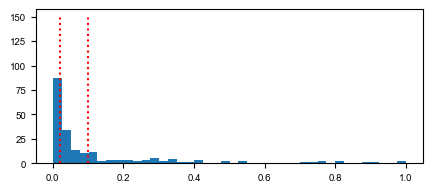

In [33]:
small_cutoff = 0.02
large_cutoff = 0.10

fig, ax = plt.subplots(figsize = (5, 2))

real_df = df.query('scenario == @experimental_scenario')
ax.hist(real_df['init_freq'], bins=40)
ax.vlines(x=small_cutoff, ymin=0, ymax=150, colors='r', linestyles='dotted', zorder=1)
ax.vlines(x=large_cutoff, ymin=0, ymax=150, colors='r', linestyles='dotted', zorder=1)

In [34]:
print(f"""\
{100*(real_df['init_freq'] < small_cutoff).mean():.1f}% of clones have a size below {small_cutoff:.2f}, \
{100*((real_df['init_freq'] > small_cutoff) & (real_df['init_freq'] < large_cutoff)).mean():.1f}% \
have a size between {small_cutoff:.2f} and {large_cutoff:.2f}, and \
{100*(real_df['init_freq'] > large_cutoff).mean():.1f}% of clones have a size above {large_cutoff:.2f}.\
""")

36.8% of clones have a size below 0.02, 34.3% have a size between 0.02 and 0.10, and 28.9% of clones have a size above 0.10.


In [35]:
df.loc[df['init_freq'] < large_cutoff, 'tertile'] = 'medium'
df.loc[df['init_freq'] < small_cutoff, 'tertile'] = 'small'
df.loc[df['init_freq'] >= large_cutoff, 'tertile'] = 'large'

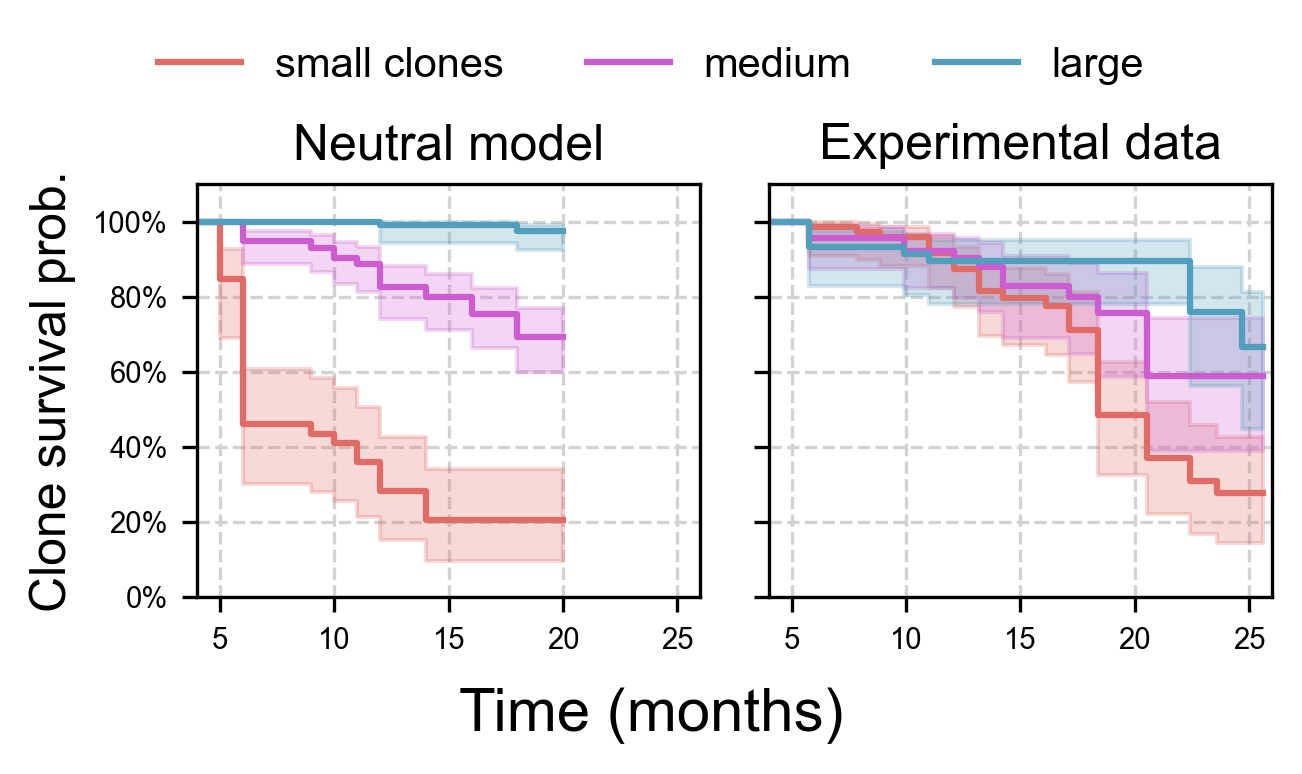

In [36]:
fig, ax = plt.subplots(1, 2, figsize=(4.5, 2.5), dpi = 300, sharey=True)

n_experimental_fish = 30
compare_scenario = 'n1000_r3_y6'

kmf = dict()
subset = dict()
for i, s in enumerate([compare_scenario, experimental_scenario]):
    # Filter the DataFrame
    
    # Instantiate the KaplanMeierFitter
    kmf[s, 'sm'] = KaplanMeierFitter()
    kmf[s, 'md'] = KaplanMeierFitter()
    kmf[s, 'lg'] = KaplanMeierFitter()

    data = df.query('scenario == @s')
    if s == experimental_scenario:
        subset[s, 'sm'] = data.query('tertile == "small"')
        subset[s, 'md'] = data.query('tertile == "medium"')
        subset[s, 'lg'] = data.query('tertile == "large"')
    else:
        # subset 'fish <= 30' so that we are comparing similar amounts of
        # experimental & real data.
        subset[s, 'sm'] = data.query('tertile == "small" and fish <= @n_experimental_fish')
        subset[s, 'md'] = data.query('tertile == "medium" and fish <= @n_experimental_fish')
        subset[s, 'lg'] = data.query('tertile == "large" and fish <= @n_experimental_fish')

    sm, md, lg = subset[s, 'sm'], subset[s, 'md'], subset[s, 'lg']
    
    # Fit the model — assuming all events are observed (no censoring)
    kmf[s, 'sm'].fit(durations = sm['last_time'], event_observed = sm['died_early'])
    kmf[s, 'md'].fit(durations = md['last_time'], event_observed = md['died_early'])
    kmf[s, 'lg'].fit(durations = lg['last_time'], event_observed = lg['died_early'])
    
    # Plot the survival curve
    kmf[s, 'sm'].plot_survival_function(ax = ax[i], label='small clones', color = '#e06b67')
    kmf[s, 'md'].plot_survival_function(ax = ax[i], label='medium', color = '#cd5cd1')
    kmf[s, 'lg'].plot_survival_function(ax = ax[i], label='large', color = '#519ebd')
    
    ax[i].set_xlabel('')
    
    ax[i].grid(True, linestyle='--', linewidth=0.8, color='lightgray')
    ax[i].set_axisbelow(True) 
    ax[i].set_xticks([5, 10, 15, 20, 25])
    ax[i].set_xlim([4, 26])
    ax[i].set_ylim([0, 1.1])
    ax[i].set_title('Neutral model' if i == 0 else 'Experimental data')
    ax[i].legend_.remove()

ax[0].set_ylabel('Clone survival prob.')
ax[0].yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))

# After plotting all curves
handles, labels = ax[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.08), ncol=3, frameon=False)
fig.supxlabel("Time (months)", y=0.1)

plt.tight_layout()
plt.savefig('./images/survivorship-tertile.svg', transparent = True, bbox_inches = 'tight')

In [38]:
df[df['scenario'].isin([experimental_scenario, compare_scenario])].groupby('scenario').agg({'died_early': 'mean'})
# Slightly more of the simulations died early in this comparison.

,died_early
scenario,
full_pipeline_trunc,0.284314
n1000_r3_y6,0.270115


In [39]:
from lifelines import CoxPHFitter

# Subset to relevant scenarios
df_sub = df[df['scenario'].isin([experimental_scenario, compare_scenario])].copy()

# Ensure 'scenario' is treated as a categorical variable
df_sub['scenario'] = df_sub['scenario'].astype('category')

# Fit Cox model with interaction
cph = CoxPHFitter()
cph.fit(df_sub, duration_col='last_time', event_col='died_early', formula='init_freq * scenario')

# Print results
print("Interaction model: init_freq × scenario")
cph.print_summary()

Interaction model: init_freq × scenario


<lifelines.CoxPHFitter: fitted with 1074 total observations, 781 right-censored observations>
             duration col = 'last_time'
                event col = 'died_early'
      baseline estimation = breslow
   number of observations = 1074
number of events observed = 293
   partial log-likelihood = -1718.05
         time fit was run = 2025-12-09 17:05:01 UTC

---
                                    coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                           
init_freq                          -2.83      0.06      1.15           -5.09           -0.58                0.01                0.56
scenario[T.n1000_r3_y6]             1.86      6.42      0.20            1.47            2.25                4.35                9.48
init_freq:scenario[T.n1000_r3_y6] -30.69      0.00      2.69          -35.96          -25.43                0.00                0.00

                                   cmp to      z      p  -log2(p)
covariate                                                        
init_freq                            0.00  -2.46   0.01      6.18
scenario[T.n1000_r3_y6]              0.00   9.35 <0.005     66.58
init_freq:scenario[T.n1000_r3_y6]    0.00 -11.42 <0.005     97.99
---
Concordance = 0.85
Partial AIC = 3442.11
log-likelihood ratio test = 448.98 on 3 df
-log2(p) of ll-ratio test = 319.78

In [40]:
# Cox proportional hazards model with `init_freq` as covariate

# Subset for 'real'
df_real = df[df['scenario'] == experimental_scenario]
cph_real = CoxPHFitter()
cph_real.fit(df_real[['last_time', 'died_early', 'init_freq']], duration_col='last_time', event_col='died_early')
print("Results for scenario: real")
cph_real.print_summary()

Results for scenario: real


<lifelines.CoxPHFitter: fitted with 204 total observations, 146 right-censored observations>
             duration col = 'last_time'
                event col = 'died_early'
      baseline estimation = breslow
   number of observations = 204
number of events observed = 58
   partial log-likelihood = -257.65
         time fit was run = 2025-12-09 17:05:32 UTC

---
           coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                  
init_freq -2.97      0.05      1.16           -5.25           -0.70                0.01                0.50

           cmp to     z    p  -log2(p)
covariate                             
init_freq    0.00 -2.56 0.01      6.60
---
Concordance = 0.60
Partial AIC = 517.30
log-likelihood ratio test = 11.43 on 1 df
-log2(p) of ll-ratio test = 10.44